# Bus Corridor Simulator

A six-stop urban bus route with ten scheduled buses in the reference run. This notebook measures how a temporary road delay spreads through the corridor and affects passenger waiting. It begins with hand-calculated checks, then compares two deterministic runs that differ only by one road delay.

## 1. Problem and question

When one bus loses time on the road, passengers accumulate at the next stop. The later bus can therefore board more people and occupy the berth for longer. A following bus that reaches the occupied berth waits in a separate bus queue.

The long-term question is whether a small adjustment to release times can lower passenger delay. Here we establish the normal-service model and diagnose its response to a road disruption.

**Route:** Origin → Market → School → Junction → Health Centre → Terminal. Stop names describe a synthetic corridor. Distances and demand are assumed, with no claim that they describe a measured route.

## 2. Model, assumptions and equations

Each stop has one berth and a first-in-first-out bus queue. Passengers enter at an assigned origin and leave at an assigned downstream destination. At the start of service, alighting passengers leave and waiting passengers board. The bus occupies the berth for the remaining dwell. Passengers arriving later wait for another bus. The model uses unlimited seating and one direction of travel.

For bus $i$ on link $j$, its nominal arrival is departure time plus running time. A bus cannot pass the bus ahead on a link, so the realised arrival also respects the preceding realised link arrival $	au_{i-1,j}$:

$$\tau_{i,j}=\max\bigl(t_{i,j}^{\mathrm{departure}}+r_{i,j},\ \tau_{i-1,j}+1\bigr).$$

The second term is omitted for the first bus on the link. The one-second separation is an assumed minimum, and time added by this rule counts as running time. At a stop, boarding/alighting counts $B$ and $A$ determine the duration in seconds:

$$d=d_0+\beta_b B+\beta_a A.$$

The example uses the rural Kandy reference coefficients $d_0=5.264$ s, $\beta_b=2.136$ s per boarding and $\beta_a=1.503$ s per alighting. Their use here is a scenario assumption. Hand checks use integer coefficients. Alighting and boarding timestamps are both defined at service start, so the passenger's measure ends when alighting starts.

$$W=t_{\mathrm{board}}-t_{\mathrm{arrival}},\quad I=t_{\mathrm{alight}}-t_{\mathrm{board}},\quad J=W+I.$$

Next-event time advance and FIFO queueing are used in this version. The input lists are fixed so timing can be audited exactly. Repeated stochastic comparisons and the departure controller will build on the same timing and passenger records.

## 3. Implementation

The configuration is a list of stop names, one running time per link, ordered bus dispatches, and a passenger manifest. Number stops from zero. An event heap sorts by time, event priority and insertion order. At a shared timestamp, berth release and arrivals occur before service starts. Each bus visit records its arrival, start of service, boardings, alightings and departure.

In [1]:
from collections import deque
from heapq import heappop, heappush
from itertools import count
from statistics import fmean

EVENT_PRIORITY = {
    "berth_release": 0,
    "passenger_arrival": 1,
    "bus_arrival": 2,
    "service_start": 3,
}
KANDY_DWELL = (5.264, 2.136, 1.503)


def simulate_corridor(
    stops, running_times, dispatches, trips, *, dwell=KANDY_DWELL, disruption=None
):
    """Run one corridor scenario. All times are in seconds."""
    # Each trip contains its arrival time, origin index and destination index.
    if len(stops) != len(running_times) + 1:
        raise ValueError("Give one running time per link between stops.")
    if any(t <= 0 for t in running_times) or tuple(sorted(dispatches)) != tuple(dispatches):
        raise ValueError("Link times must be positive and dispatches must be ordered.")
    if not dispatches or dispatches[0] < 0:
        raise ValueError("Give at least one nonnegative dispatch time.")
    fixed_dwell, seconds_per_boarding, seconds_per_alighting = dwell
    if fixed_dwell <= 0 or min(seconds_per_boarding, seconds_per_alighting) < 0:
        raise ValueError("Fixed dwell must be positive and passenger coefficients nonnegative.")
    if disruption is not None:
        delayed_bus, delayed_link, extra_time = disruption
        if not (1 <= delayed_bus <= len(dispatches)
                and 0 <= delayed_link < len(running_times) and extra_time >= 0):
            raise ValueError("Disruption must identify an existing bus, link and nonnegative delay.")

    calendar = []
    sequence = count()
    trace = []
    # Buses queue for a berth. Passengers wait separately on the platform.
    bus_queues = [deque() for _ in stops]
    platform_queues = [deque() for _ in stops]
    berth_bus = [None for _ in stops]
    last_link_arrival = [float("-inf") for _ in running_times]
    bus_visits = {}
    passengers = []
    onboard = {bus: [] for bus in range(1, len(dispatches) + 1)}

    def schedule(time, event, subject, stop):
        heappush(calendar, (time, EVENT_PRIORITY[event], next(sequence), event, subject, stop))

    for bus, dispatch in enumerate(dispatches, start=1):
        schedule(dispatch, "bus_arrival", bus, 0)
    for rider, (arrival, origin, destination) in enumerate(trips):
        if arrival < 0 or not 0 <= origin < destination < len(stops):
            raise ValueError("Passenger trips need a nonnegative time and a downstream destination.")
        passengers.append({
            "arrival": arrival, "origin": origin, "destination": destination,
            "board": None, "alight": None, "bus": None,
        })
        schedule(arrival, "passenger_arrival", rider, origin)

    previous_time = 0
    while calendar:
        now, _, _, event, subject, stop = heappop(calendar)
        assert now >= previous_time
        previous_time = now
        trace.append((now, event, subject, stop))
        queue = bus_queues[stop]

        if event == "passenger_arrival":
            platform_queues[stop].append(subject)

        elif event == "bus_arrival":
            bus_visits[subject, stop] = {"arrival": now}
            queue.append(subject)
            if berth_bus[stop] is None and len(queue) == 1:
                schedule(now, "service_start", subject, stop)

        elif event == "service_start":
            front_bus = queue.popleft()
            assert front_bus == subject and berth_bus[stop] is None
            berth_bus[stop] = subject

            remaining = []
            alightings = 0
            for rider in onboard[subject]:
                passenger = passengers[rider]
                if passenger["destination"] == stop:
                    passenger["alight"] = now
                    alightings += 1
                else:
                    remaining.append(rider)

            boardings = len(platform_queues[stop])
            while platform_queues[stop]:
                rider = platform_queues[stop].popleft()
                passengers[rider]["board"] = now
                passengers[rider]["bus"] = subject
                remaining.append(rider)
            onboard[subject] = remaining

            duration = (
                fixed_dwell
                + seconds_per_boarding * boardings
                + seconds_per_alighting * alightings
            )
            bus_visits[subject, stop].update(
                service_start=now, boardings=boardings, alightings=alightings
            )
            schedule(now + duration, "berth_release", subject, stop)

        elif event == "berth_release":
            assert berth_bus[stop] == subject
            bus_visits[subject, stop]["departure"] = now
            berth_bus[stop] = None
            if queue:
                schedule(now, "service_start", queue[0], stop)
            if stop < len(running_times):
                next_arrival = now + running_times[stop]
                if disruption is not None and subject == delayed_bus and stop == delayed_link:
                    next_arrival += extra_time
                # Keep buses in departure order on each link.
                next_arrival = max(next_arrival, last_link_arrival[stop] + 1)
                last_link_arrival[stop] = next_arrival
                schedule(next_arrival, "bus_arrival", subject, stop + 1)

    completed = sum(rider["alight"] is not None for rider in passengers)
    still_waiting = sum(map(len, platform_queues))
    assert completed + still_waiting + sum(map(len, onboard.values())) == len(passengers)
    assert not any(onboard.values()), "All boarded passengers must alight by the terminal."
    assert len(bus_visits) == len(stops) * len(dispatches)
    return bus_visits, passengers, trace

## 4. Verification

The one-berth case uses two buses to isolate the expected 20-second wait, then a third bus to exercise the exact timestamp tie. Bus 1 arrives at 70 s and departs at 100 s. Bus 2 arrives at 80 s and keeps its place when Bus 3 arrives at the moment the berth frees. The three-stop test checks a complete journey and two consecutive berth queues in the same engine.

In [2]:
# One berth, fixed 30 s dwell. Bus 3 arrives at exactly the first berth release.
visits, _, trace = simulate_corridor(
    ("Test stop",), (), (70, 80, 100), (), dwell=(30, 0, 0)
)
assert visits[1, 0]["departure"] == 100
assert visits[2, 0]["service_start"] - visits[2, 0]["arrival"] == 20
assert visits[3, 0]["service_start"] == 130
assert [event for time, event, _, _ in trace if time == 100] == [
    "berth_release", "bus_arrival", "service_start",
]
print("PASS: 20 s berth wait and FIFO at a simultaneous release and arrival.")

# Hand trace with d = 10 + 2B + A, two road links of 20 and 30 seconds.
# Passenger 1 boards at 0 s; Passenger 2 arrives at 30 s and boards at 32 s.
# Both reach their destination at 74 s. The second bus queues at both downstream stops.
visits, riders, _ = simulate_corridor(
    ("Origin", "Middle", "Terminal"), (20, 30), (0, 5),
    ((0, 0, 2), (30, 1, 2)), dwell=(10, 2, 1)
)
assert visits[1, 1]["arrival"] == 32
assert visits[2, 1]["service_start"] - visits[2, 1]["arrival"] == 2
assert visits[2, 2]["service_start"] - visits[2, 2]["arrival"] == 2
assert [(rider["board"], rider["alight"]) for rider in riders] == [(0, 74), (32, 74)]
assert all(rider["bus"] == 1 for rider in riders)
print("PASS: full trips take 74 s and 44 s, with 0 s and 2 s platform waits.")

PASS: 20 s berth wait and FIFO at a simultaneous release and arrival.
PASS: full trips take 74 s and 44 s, with 0 s and 2 s platform waits.


## 5. Reference corridor experiment

Run ten buses at 80-second dispatch intervals. Generate a fixed passenger schedule at the five boarding stops and assign downstream destinations. Replay it twice. In the disrupted run, Bus 4 gets an additional 100 seconds on the first road link. All other specified inputs match.

These runs illustrate what a disturbance does to service. They do not estimate an average causal effect over random conditions.

In [3]:
STOPS = ("Origin", "Market", "School", "Junction", "Health Centre", "Terminal")
DISTANCE_KM = (0.0, 0.5, 1.1, 1.7, 2.3, 2.9)
RUNNING_TIMES = (60, 70, 75, 70, 80)
DISPATCHES = tuple(range(0, 800, 80))
ARRIVAL_INTERVALS = (13, 8, 10, 11, 12)

# Stagger the first arrivals by stop. Two in every three riders travel to the
# terminal, and the third rider travels one stop. This is a scenario assumption.
TRIPS = []
for origin, interval in enumerate(ARRIVAL_INTERVALS):
    for number, arrival in enumerate(range(5 + 7 * origin, 635, interval)):
        destination = origin + 1 if number % 3 == 0 else len(STOPS) - 1
        TRIPS.append((arrival, origin, destination))

runs = {
    "Normal service": simulate_corridor(STOPS, RUNNING_TIMES, DISPATCHES, TRIPS),
    "Road delay on Bus 4": simulate_corridor(
        STOPS, RUNNING_TIMES, DISPATCHES, TRIPS, disruption=(4, 0, 100)
    ),
}

print(f"{len(STOPS)} stops | {len(DISPATCHES)} buses | {len(TRIPS)} passenger arrivals per run")
print(f"{'Scenario':<24} {'Completed':>9} {'Wait (s)':>10} {'Journey (s)':>12} {'Berth wait (s)':>15}")
for label, (visits, riders, _) in runs.items():
    assert all(rider["alight"] is not None for rider in riders), "Extend service to finish this cohort."
    mean_wait = fmean(rider["board"] - rider["arrival"] for rider in riders)
    mean_journey = fmean(rider["alight"] - rider["arrival"] for rider in riders)
    mean_berth_wait = fmean(visit["service_start"] - visit["arrival"] for visit in visits.values())
    print(f"{label:<24} {len(riders):9d} {mean_wait:10.1f} {mean_journey:12.1f} {mean_berth_wait:15.1f}")

print("\nMarket stop, road-delay run")
for bus in (4, 5):
    visit = runs["Road delay on Bus 4"][0][bus, 1]
    wait = visit["service_start"] - visit["arrival"]
    print(f"Bus {bus}: {visit['boardings']} boardings, {wait:.1f} s waiting for its berth")

6 stops | 10 buses | 296 passenger arrivals per run
Scenario                 Completed   Wait (s)  Journey (s)  Berth wait (s)
Normal service                 296       64.6        327.8             3.6
Road delay on Bus 4            296       83.7        382.2            15.8

Market stop, road-delay run
Bus 4: 23 boardings, 0.0 s waiting for its berth
Bus 5: 7 boardings, 57.9 s waiting for its berth


### Time–distance figure

Each line is one bus. Flat segments show time at a stop, including berth wait and dwell. The highlighted buses are the delayed Bus 4 and its follower. Panels use the same stop positions and time scale, so their gaps and travel patterns are directly comparable.

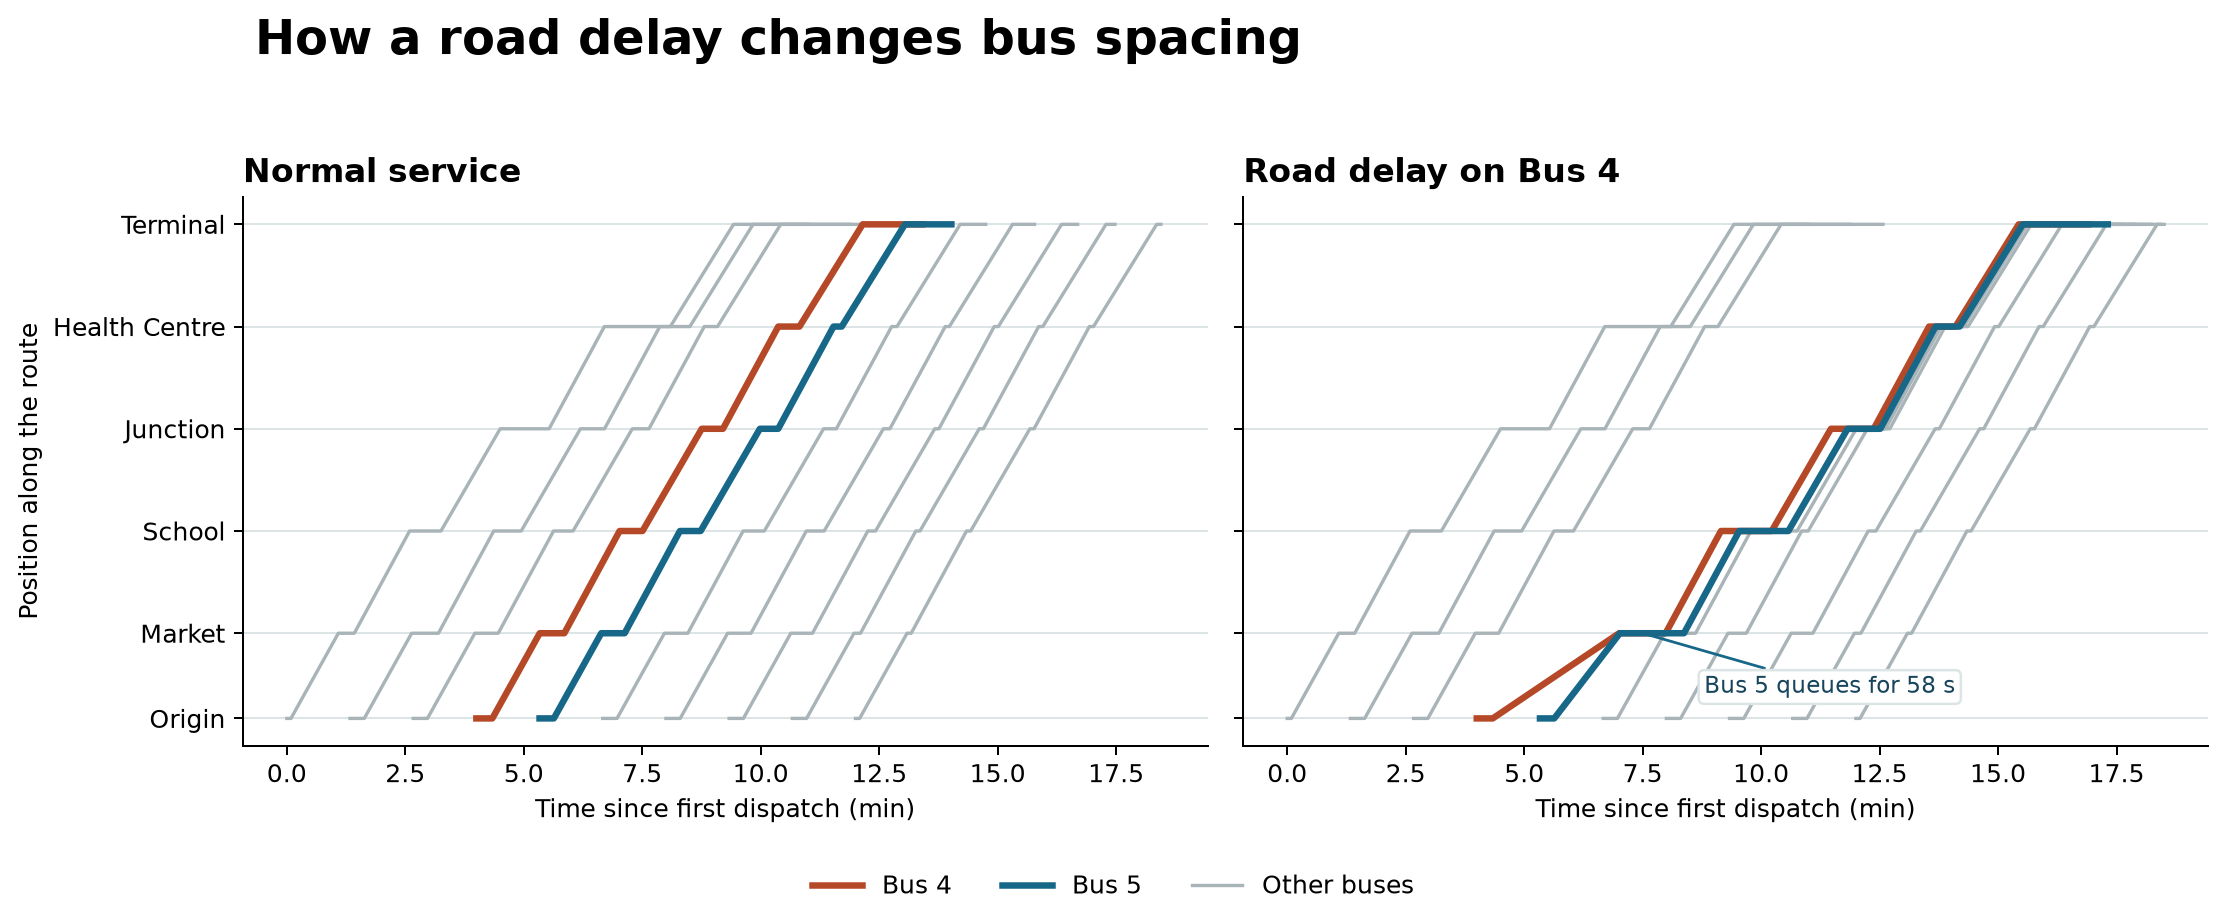

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

figure, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharex=True, sharey=True)
palette = {4: "#b54826", 5: "#176789"}

for axis, (label, (visits, _, _)) in zip(axes, runs.items()):
    for bus in range(1, len(DISPATCHES) + 1):
        times, positions = [], []
        for index, distance in enumerate(DISTANCE_KM):
            visit = visits[bus, index]
            times.extend((visit["arrival"] / 60, visit["departure"] / 60))
            positions.extend((distance, distance))
        axis.plot(
            times, positions,
            color=palette.get(bus, "#a9b4b8"),
            linewidth=2.6 if bus in palette else 1.35,
            zorder=3 if bus in palette else 2,
        )
    axis.set_title(label, loc="left", fontsize=13, fontweight="bold")
    axis.set_xlabel("Time since first dispatch (min)")
    axis.set_yticks(DISTANCE_KM, STOPS)
    axis.grid(axis="y", color="#dce4e5", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.set_ylim(-0.16, 3.06)

# Label the berth wait from the recorded event times.
queued = runs["Road delay on Bus 4"][0][5, 1]
queue_midpoint = (queued["arrival"] + queued["service_start"]) / 120
queue_seconds = queued["service_start"] - queued["arrival"]
axes[1].annotate(
    f"Bus 5 queues for {queue_seconds:.0f} s",
    xy=(queue_midpoint, DISTANCE_KM[1]), xytext=(8.8, 0.15),
    fontsize=9, color="#17455c",
    bbox={"boxstyle": "round,pad=0.25", "fc": "white", "ec": "#dce4e5"},
    arrowprops={"arrowstyle": "-", "color": "#176789", "lw": 1.1},
)
axes[0].set_ylabel("Position along the route")
legend = [Line2D([0], [0], color=color, lw=2.6, label=f"Bus {bus}")
          for bus, color in palette.items()]
legend.append(Line2D([0], [0], color="#a9b4b8", lw=1.35, label="Other buses"))
figure.suptitle("How a road delay changes bus spacing", x=0.12, y=0.96, ha="left",
                fontsize=19, fontweight="bold")
figure.legend(handles=legend, loc="lower center", ncol=3, frameon=False)
figure.tight_layout(rect=(0, 0.07, 1, 0.92))
Path("figures").mkdir(exist_ok=True)
figure.savefig("figures/corridor-time-distance.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Discussion and limitations

The pair introduces one disturbance while holding passenger arrival times and destinations fixed. It illustrates how one run develops a bus queue and how passenger delay can change. The reported averages compare this finite passenger cohort and include every completed journey.

A straight route, one berth per stop, assumed demand, no passing, no seat limit, and the transferred dwell coefficients define the scope. The later stochastic model will vary running times and passenger arrivals, preserve matched inputs, and compare a no-holding baseline with capped departures across replications.

## 7. References

- [Herath et al. (2024), dwell equation 9 and table 3](https://www.jstage.jst.go.jp/article/easts/15/0/15_2109/_pdf/-char/en)
- [Jayasinghe et al. (2023), Galle Road bus operations](https://doi.org/10.4038/jsalt.v3i1.57)
- [Shen et al. (2026), headway irregularity and stop queues](https://doi.org/10.1016/j.tra.2025.104752)